# 02 · ARIMAX, Granger causality, forecasting and VAR

**Question:** once we know elk follow a random walk with drift (notebook 01), do wolves, bison, vegetation, climate or hunting explain the year-to-year changes?

**Target:** y_t = Δ log(elk)_t = log E_t − log E_{t−1} (≈ % change in elk from one winter count to the next).
Notebook 01 showed y_t is white noise, so the ARIMAX is

  y_t = μ + β₁x₁ + … + β_k x_k + ε_t,  ε_t white noise

i.e. an **ARIMAX(0,1,0)** on log elk. (Sensitivity check: MA(2) errors, the close alternative from notebook 01.)

Sections
1. Data and time alignment
2. Making every regressor stationary
3. One variable at a time (screening)
4. Granger causality tests
5. The full ARIMAX model + diagnostics (residual ACF, Ljung–Box, ARCH)
6. Reduced model (wolves only) and robustness checks
7. Rolling-origin forecast evaluation (2011–2025)
8. VAR: elk and wolves as a two-way system
9. Summary

In [1]:
import warnings
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.api import VAR
from statsmodels.tsa.stattools import adfuller, kpss, grangercausalitytests

warnings.filterwarnings("ignore")
pd.set_option("display.width", 140)
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
FIG = ROOT / "reports" / "figures"; FIG.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(ROOT / "data" / "processed" / "yellowstone_master_ts_flagged.csv", index_col="Year")
harv = pd.read_csv(ROOT / "data" / "raw" / "elk_harvest_northern.csv", index_col="Year")
df = df.join(harv[["Harvest_Total", "Harvest_source", "Harvest_imputed"]])
df[["Elk_Count", "Wolf_Northern", "Bison_Count", "NDVI", "Precip_Annual", "PDSI_Annual", "Harvest_Total"]].tail()

,Elk_Count,Wolf_Northern,Bison_Count,NDVI,Precip_Annual,PDSI_Annual,Harvest_Total
Year,,,,,,,
2021,4609.0,55,3830,0.5194,525.0396,-2.0878,367
2022,6673.0,60,4507,0.5796,578.8747,0.0141,318
2023,5976.0,69,3616,0.5939,603.1698,0.9545,335
2024,5597.0,57,4550,0.5547,521.7272,-2.0755,289
2025,7226.0,53,5300,0.5136,521.7272,-2.0755,346


## Time alignment
Counts are labelled by winter year, but survey dates vary from January to April. Prior-year wolves, bison, NDVI and calendar-year climate are used; harvest uses season ending t. Whole-winter severity and completed harvest are conditional retrospective inputs, not established real-time information.


In [2]:
Y = np.log(df["Elk_Count"]).diff().rename("dlog_elk")
raw = pd.DataFrame({
    "wolves":   df["Wolf_Northern"].shift(1),
    "bison":    df["Bison_Count"].shift(1),
    "ndvi":     df["NDVI"].shift(1),
    "precip":   df["Precip_Annual"].shift(1),
    "pdsi":     df["PDSI_Annual"].shift(1),
    "harvest_rate": df["Harvest_Total"] / df["Elk_Count"].shift(1),   # share of last winter's herd removed
})
raw.loc[1990:2000].round(3)

,wolves,bison,ndvi,precip,pdsi,harvest_rate
Year,,,,,,
1990,0.0,432.0,0.464,604.584,-1.760,0.077
1991,0.0,818.0,0.476,486.002,-1.836,0.068
1992,0.0,822.0,0.498,602.013,0.378,0.326
1993,0.0,681.0,0.496,583.997,-0.683,0.160
1994,0.0,636.0,0.512,601.566,2.126,0.030
1995,0.0,1140.0,0.472,571.140,-2.536,0.133
1996,21.0,866.0,0.543,686.753,2.664,0.102
1997,30.0,860.0,0.496,672.077,1.519,0.220
1998,40.0,455.0,0.568,696.162,3.531,0.124


## 2. Make every regressor stationary

Same rule as notebook 01: ADF at lags 0, 1, 2 (stationary if it rejects at ≥ 2 of 3) plus KPSS. Non-stationary regressors are differenced. Regressing a stationary y on a trending x is how spurious results happen.

Harvest is entered as a **rate** (harvest ÷ previous elk count): removing 1,000 elk matters far more from a herd of 5,000 than from 19,000, and log-growth responds to the fraction removed.

In [3]:
def stationarity(x):
    x = x.dropna()
    ps = [adfuller(x, maxlag=l, autolag=None)[1] for l in (0, 1, 2)]
    adf = sum(p < 0.05 for p in ps) >= 2
    k = kpss(x, regression="c", nlags="auto")[1] < 0.05
    verdict = "stationary" if adf and not k else "non-stationary" if (not adf and k) else "inconclusive"
    return dict(ADF_p_lag0=ps[0], ADF_p_lag1=ps[1], ADF_p_lag2=ps[2], KPSS_rejects=k, verdict=verdict)

st = pd.DataFrame({c: stationarity(raw[c]) for c in raw}).T
st

,ADF_p_lag0,ADF_p_lag1,ADF_p_lag2,KPSS_rejects,verdict
wolves,0.438058,0.394571,0.562267,True,non-stationary
bison,0.957073,0.98654,0.988343,True,non-stationary
ndvi,0.005099,0.045301,0.187685,False,stationary
precip,0.000104,0.009125,0.167555,False,stationary
pdsi,0.000778,0.039152,0.05345,False,stationary
harvest_rate,0.000118,0.027355,0.337514,True,inconclusive


In [4]:
import sys
if str(ROOT / "scripts") not in sys.path: sys.path.insert(0, str(ROOT / "scripts"))
from analysis import features, load_data, rolling
_, X, transformation_audit = features(load_data())
X = X.drop(columns="severity")  # six-driver legacy specification
transformation_audit


,variable,stage,difference_applied,n,ADF_p0,ADF_p1,ADF_p2,KPSS_p,verdict
0,d_wolves,before,False,40,2.901149e-07,6.710788e-08,0.026268,0.100000,stationary
1,d_wolves,after,False,40,2.901149e-07,6.710788e-08,0.026268,0.100000,stationary
2,d_logbison,before,False,40,2.823022e-15,1.457981e-05,0.000340,0.100000,stationary
3,d_logbison,after,False,40,2.823022e-15,1.457981e-05,0.000340,0.100000,stationary
4,ndvi,before,False,41,5.099174e-03,4.530114e-02,0.187685,0.067194,stationary
5,ndvi,after,False,41,5.099174e-03,4.530114e-02,0.187685,0.067194,stationary
6,precip,before,False,41,1.043747e-04,9.124512e-03,0.167555,0.100000,stationary
7,precip,after,False,41,1.043747e-04,9.124512e-03,0.167555,0.100000,stationary
8,pdsi,before,False,41,7.777895e-04,3.915212e-02,0.053450,0.100000,stationary
9,pdsi,after,False,41,7.777895e-04,3.915212e-02,0.053450,0.100000,stationary


Transforms follow the stationarity rule. Wolves retain units per 10 wolves, bison uses log differences; other inputs are standardised after any required differencing.


## 3. One variable at a time

Each regressor alone: y_t = μ + βx_t + ε_t. This is a screen, not the final answer. With 6 tests at the 5 % level, about 0.3 false positives are expected by chance, so a p-value near 0.05 is weak evidence on its own.

In [5]:
def fit_arimax(y, X=None, order=(0, 0, 0)):
    d = pd.concat([y, X], axis=1).dropna() if X is not None else y.dropna().to_frame()
    exog = d.drop(columns=y.name) if X is not None else None
    return ARIMA(d[y.name], exog=exog if exog is not None and len(exog.columns) else None, order=order, trend="c").fit(), d

rows = []
for c in X:
    res, d = fit_arimax(Y, X[[c]])
    rows.append(dict(variable=c, beta=res.params[c], pct_effect=100 * res.params[c],
                     p=res.pvalues[c], n=len(d), years=f"{d.index.min()}–{d.index.max()}"))
screen = pd.DataFrame(rows).set_index("variable")
screen.round(3)

,beta,pct_effect,p,n,years
variable,,,,,
d_wolves,-0.031,-3.053,0.120,40,1986–2025
d_logbison,-0.046,-4.556,0.653,40,1986–2025
ndvi,0.011,1.087,0.762,41,1985–2025
precip,0.000,0.008,0.998,41,1985–2025
pdsi,-0.006,-0.598,0.839,41,1985–2025
harvest_rate,-0.034,-3.375,0.324,40,1986–2025


## 4. Granger causality

"x Granger-causes elk" means: past values of x improve the prediction of elk changes beyond what past elk changes already give. It tests prediction, not biological cause. Lags 1 and 2 are tested; the F-test p-value is reported.

Note the regressors in `X` are already aligned to the 12 months before each count, so "lag 1" here means the window directly before the count.

In [6]:
# Contemporary annual system; Granger supplies its own lag. Do not unshift harvest.
g = []
for c in X:
    series = X[c] if c == 'harvest_rate' else X[c].shift(-1)
    d = pd.concat([Y, series.rename(c)], axis=1).dropna()
    for target, predictor in [('dlog_elk', c), (c, 'dlog_elk')]:
        out = grangercausalitytests(d[[target, predictor]], maxlag=2)
        for lag in (1, 2):
            g.append({'target':target, 'predictor':predictor, 'lag':lag, 'p':out[lag][0]['ssr_ftest'][1]})
granger = pd.DataFrame(g)
granger


,target,predictor,lag,p
0,dlog_elk,d_wolves,1,0.173808
1,dlog_elk,d_wolves,2,0.158634
2,d_wolves,dlog_elk,1,0.763063
3,d_wolves,dlog_elk,2,0.077562
4,dlog_elk,d_logbison,1,0.569649
5,dlog_elk,d_logbison,2,0.846132
6,d_logbison,dlog_elk,1,0.615810
7,d_logbison,dlog_elk,2,0.866819
8,dlog_elk,ndvi,1,0.730150
9,dlog_elk,ndvi,2,0.719024


## 5. Full ARIMAX model

All six regressors at once, white-noise errors (the chosen model from notebook 01). Then the same model with MA(2) errors as a sensitivity check.

In [7]:
full, dfull = fit_arimax(Y, X)
print(full.summary().tables[1])
print(f"n = {len(dfull)} ({dfull.index.min()}–{dfull.index.max()})")
base, _ = fit_arimax(Y.loc[dfull.index])
print(f"Residual variance: drift only {base.params['sigma2']:.4f}  ->  full ARIMAX {full.params['sigma2']:.4f}"
      f"  ({100*(1-full.params['sigma2']/base.params['sigma2']):.0f}% explained)")

                   coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------
const           -0.0152      0.035     -0.428      0.669      -0.085       0.054
d_wolves        -0.0288      0.029     -0.995      0.320      -0.085       0.028
d_logbison      -0.0337      0.137     -0.246      0.806      -0.302       0.235
ndvi             0.0165      0.049      0.335      0.737      -0.080       0.113
precip           0.0087      0.054      0.160      0.873      -0.098       0.115
pdsi            -0.0198      0.068     -0.289      0.773      -0.154       0.114
harvest_rate    -0.0285      0.037     -0.766      0.444      -0.101       0.044
sigma2           0.0250      0.006      4.271      0.000       0.014       0.036
n = 40 (1986–2025)
Residual variance: drift only 0.0279  ->  full ARIMAX 0.0250  (10% explained)


In [8]:
full_ma2, _ = fit_arimax(Y, X, order=(0, 0, 2))
comp = pd.DataFrame({"white-noise errors: β": full.params, "p": full.pvalues,
                     "MA(2) errors: β": full_ma2.params, "p ": full_ma2.pvalues}).drop(["sigma2"])
comp.round(3)

,white-noise errors: β,p,MA(2) errors: β,p
const,-0.015,0.669,-0.018,0.449
d_logbison,-0.034,0.806,-0.030,0.866
d_wolves,-0.029,0.320,-0.026,0.415
harvest_rate,-0.029,0.444,-0.027,0.608
ma.L1,NaN,NaN,-0.227,0.390
ma.L2,NaN,NaN,-0.119,0.752
ndvi,0.016,0.737,0.035,0.327
pdsi,-0.020,0.773,-0.029,0.603
precip,0.009,0.873,0.025,0.660


### Diagnostics
The residuals should be white noise (residual ACF inside the bands, Ljung–Box p > 0.05) with constant variance (ARCH test p > 0.05; if it failed, a GARCH model would be needed).

full ARIMAX: Ljung–Box p (lag 5, 8) = 0.94, 0.72;  ARCH test p = 0.16


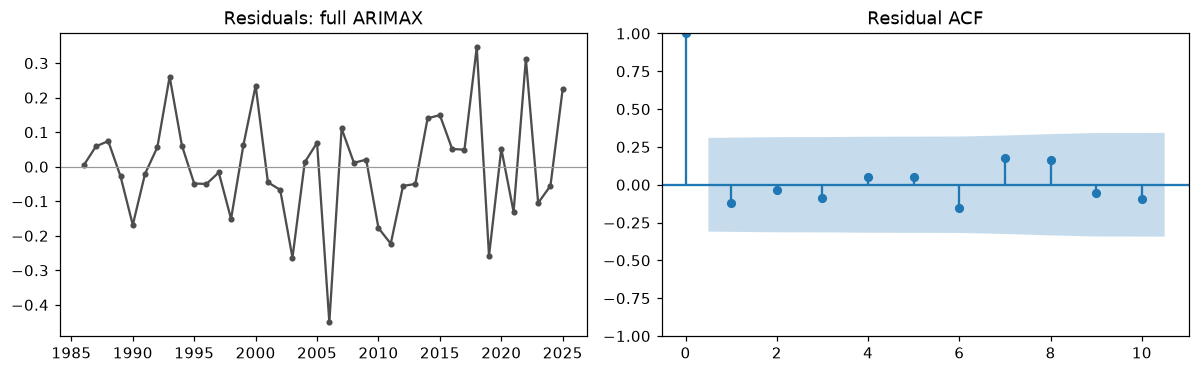

In [9]:
def diagnose(res, name, fname=None):
    r = res.resid
    lb = acorr_ljungbox(r, lags=[5, 8]).lb_pvalue.values
    arch_p = het_arch(r, nlags=2)[1]
    print(f"{name}: Ljung–Box p (lag 5, 8) = {lb[0]:.2f}, {lb[1]:.2f};  ARCH test p = {arch_p:.2f}")
    if fname:
        fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
        ax[0].plot(r.index, r, "o-", ms=3, color="0.3"); ax[0].axhline(0, color="0.6", lw=0.8)
        ax[0].set_title(f"Residuals: {name}")
        plot_acf(r, lags=10, ax=ax[1]); ax[1].set_title("Residual ACF")
        fig.tight_layout(); fig.savefig(FIG / fname, dpi=200)

diagnose(full, "full ARIMAX", "08_arimax_residuals.png")

## Reduced model and robustness
Screen-based selection is exploratory and cannot establish confirmatory p-values. All drivers and predefined wolf-only forecast models are reported in notebook 03.


In [10]:
keep = [c for c in X if screen.loc[c, "p"] < 0.05]
print("Kept:", keep)
red, dred = fit_arimax(Y, X[keep])
print(red.summary().tables[1])
diagnose(red, "reduced ARIMAX")

Kept: []
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         -0.0198      0.027     -0.728      0.467      -0.073       0.034
sigma2         0.0272      0.006      4.366      0.000       0.015       0.039
reduced ARIMAX: Ljung–Box p (lag 5, 8) = 0.82, 0.75;  ARCH test p = 0.17


In [11]:
imp = df["Elk_Count_imputed"]
real = (imp == 0) & (imp.shift(1) == 0)
checks = {}
checks["reduced (all years)"] = red
checks["(a) real counts only"], _ = fit_arimax(Y[real], X[keep])
checks["(b) up to 2015"], _ = fit_arimax(Y.loc[:2015], X[keep])
if "d_wolves" in keep:
    Xc = X[keep].drop(columns="d_wolves").assign(wolves_level=raw["wolves"] / 10)
    checks["(c) wolves in levels"], _ = fit_arimax(Y, Xc)
checks["(d) MA(2) errors"], _ = fit_arimax(Y, X[keep], order=(0, 0, 2))
rob = pd.DataFrame({k: pd.concat([v.params.drop(["const", "sigma2"]).filter(regex="^(?!ma)"),
                                  v.pvalues.drop(["const", "sigma2"]).filter(regex="^(?!ma)").add_prefix("p_")])
                    for k, v in checks.items()}).T
rob["n"] = [int(v.nobs) for v in checks.values()]
rob.round(3)

,n
reduced (all years),41
(a) real counts only,28
(b) up to 2015,31
(d) MA(2) errors,41


Previous numerical conclusions were removed because they referred to the uncorrected dataset. Read the recalculated table above.


## Conditional rolling predictions
Use the shared leakage-controlled pipeline. All four models are scored on the same verified, non-imputed target/origin pairs. Exogenous publication dates remain unverified.


In [12]:
score = rolling(load_data())
score


,model,MAE,RMSE,MAPE,n,years
0,drift,1003.794142,1261.327732,16.663013,9,"2011,2012,2013,2017,2018,2019,2023,2024,2025"
1,full_conditional,1402.128028,2084.900563,24.813450,9,"2011,2012,2013,2017,2018,2019,2023,2024,2025"
2,naive,1034.000000,1245.017983,17.540466,9,"2011,2012,2013,2017,2018,2019,2023,2024,2025"
3,wolves_only,986.391134,1244.558526,16.392559,9,"2011,2012,2013,2017,2018,2019,2023,2024,2025"


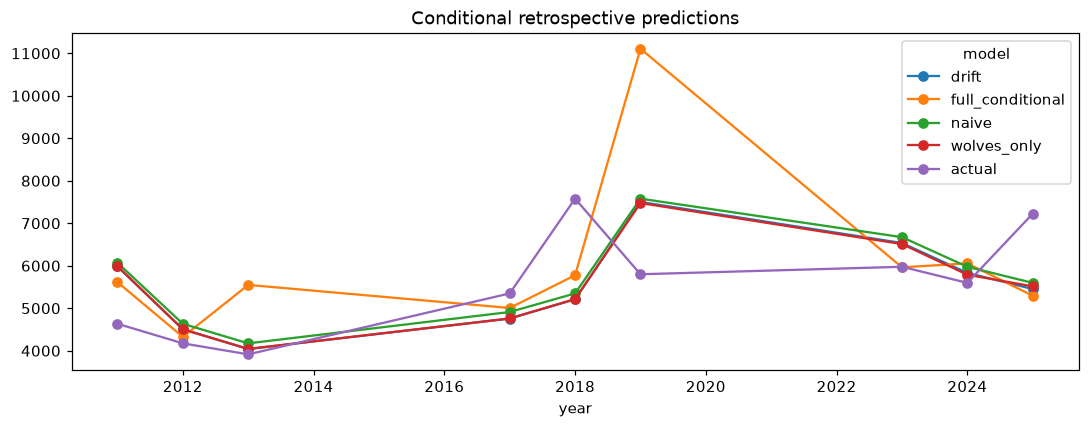

In [13]:
f = pd.read_csv(ROOT / 'reports/tables/q3_predictions.csv')
fc = f.pivot(index='year', columns='model', values='predicted')
fc['actual'] = f.groupby('year').actual.first()
ax = fc.plot(marker='o', figsize=(10,4), title='Conditional retrospective predictions')
ax.figure.tight_layout(); ax.figure.savefig(FIG / '09_rolling_forecasts.png', dpi=150)


## 8. VAR: elk and wolves as a two-way system

ARIMAX assumes wolves affect elk but not the other way round. In reality wolves also depend on elk (their prey). A VAR treats both as outcomes:

  Δlog elk_t = a₁ + b₁₁ Δlog elk_{t−1} + b₁₂ Δwolves_{t−1} + e₁
  Δwolves_t  = a₂ + b₂₁ Δlog elk_{t−1} + b₂₂ Δwolves_{t−1} + e₂

Fitted on 1996–2025 (wolves exist), lag 1 only because the sample is short.

In [14]:
w = df["Wolf_Northern"]
V = pd.DataFrame({"dlog_elk": Y, "d_wolves": w.diff() / 10}).loc[1997:].dropna()
var = VAR(V).fit(1)
print(var.summary())
for caused, causing in [("dlog_elk", "d_wolves"), ("d_wolves", "dlog_elk")]:
    t = var.test_causality(caused, [causing], kind="f")
    print(f"{causing} Granger-causes {caused}: p = {t.pvalue:.3f}")

  Summary of Regression Results   
Model:                         VAR
Method:                        OLS
Date:           Fri, 20, Nov, 2026
Time:                     01:01:18
--------------------------------------------------------------------
No. of Equations:         2.00000    BIC:                   -2.00795
Nobs:                     28.0000    HQIC:                  -2.20615
Log likelihood:          -41.3526    FPE:                   0.101087
AIC:                     -2.29343    Det(Omega_mle):       0.0824684
--------------------------------------------------------------------
Results for equation dlog_elk
                 coefficient       std. error           t-stat            prob
------------------------------------------------------------------------------
const              -0.027003         0.035077           -0.770           0.441
L1.dlog_elk        -0.222185         0.198842           -1.117           0.264
L1.d_wolves        -0.031374         0.022855           -1.373   

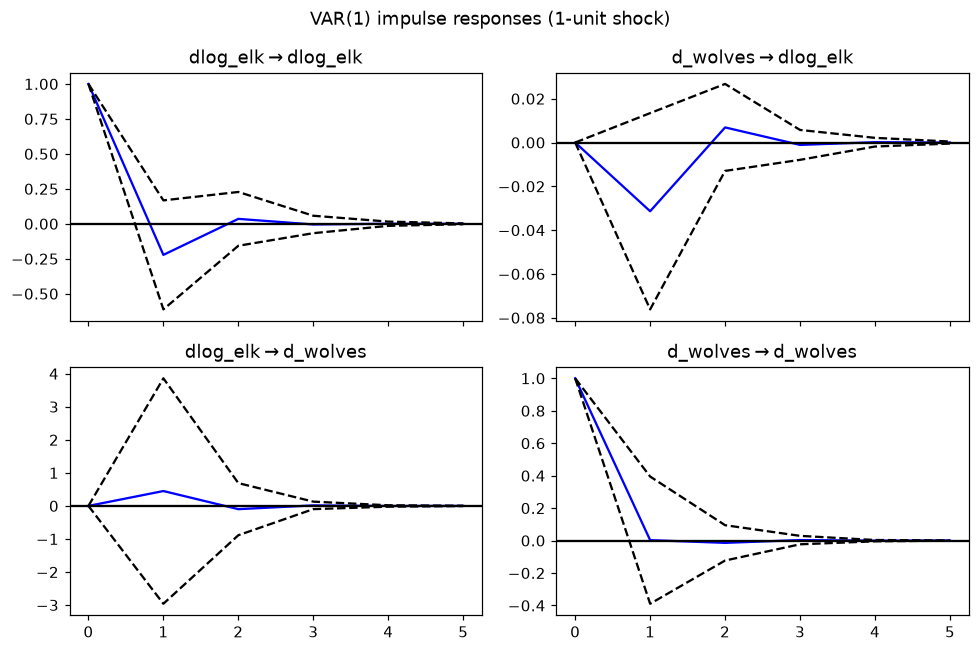

In [15]:
irf = var.irf(5)
fig = irf.plot(orth=False, figsize=(9, 6)); fig.suptitle("VAR(1) impulse responses (1-unit shock)")
fig.tight_layout(); fig.savefig(FIG / "10_var_irf.png", dpi=200)

## Updated summary
All estimates above are recomputed. Do not retain the previous claims of significant wolf effects or forecast gains. The authoritative comparison and limitations are in reports/RESULTS.md.


In [16]:
print("Screening:"); print(screen.round(3).to_string())
print("Conditional prediction scores:"); print(score.to_string(index=False))


Screening:
               beta  pct_effect      p   n      years
variable                                             
d_wolves     -0.031      -3.053  0.120  40  1986–2025
d_logbison   -0.046      -4.556  0.653  40  1986–2025
ndvi          0.011       1.087  0.762  41  1985–2025
precip        0.000       0.008  0.998  41  1985–2025
pdsi         -0.006      -0.598  0.839  41  1985–2025
harvest_rate -0.034      -3.375  0.324  40  1986–2025
Conditional prediction scores:
           model         MAE        RMSE      MAPE  n                                        years
           drift 1003.794142 1261.327732 16.663013  9 2011,2012,2013,2017,2018,2019,2023,2024,2025
full_conditional 1402.128028 2084.900563 24.813450  9 2011,2012,2013,2017,2018,2019,2023,2024,2025
           naive 1034.000000 1245.017983 17.540466  9 2011,2012,2013,2017,2018,2019,2023,2024,2025
     wolves_only  986.391134 1244.558526 16.392559  9 2011,2012,2013,2017,2018,2019,2023,2024,2025
